In [1]:
#importing the package
import numpy as np
from qutip import*
import scipy.constants as const
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

# print done


In [2]:
def collapse(a,T1,T2,wq,temperature): #for collpase operator thats used in lindblad master equation
    c = [] # declaring empty array
    g1 = 1/T1 #gamma_1
    gphi = 1/T2 - 1/(2*T1) #gamma phi

    h = const.h #plancks constant
    kb = const.k #boltzman constant
    if temperature ==0:
        n_th = 0.0
    else:
        n_th = 1.0 / (np.exp((h * wq*1e6) / ( kb * temperature)) - 1.0) #Bose-Einstein statistics

    # 1. Downward relaxation (Emission): includes (n_th + 1)
    c.append(np.sqrt(g1 * (n_th + 1)) * a)
    # 2. Upward excitation (Absorption): includes n_th
    c.append(np.sqrt(g1 * n_th) * a.dag())
    # 3. Pure Dephasing (T2/Tphi channel)
    c.append(np.sqrt(2 * gphi) * a.dag() * a)

    #After this operation we will be getting three collapse operators which will be feeded for solving the Lindblad master equation
    return c

def envelop(t,t_start,t_end,amplitude,sigma): #Generation of the gaussian envelop of desired configuration
    t_center = (t_start + t_end)/2 #where the gaussian should be centered
    v_t = 100*amplitude * np.exp(-((t - t_center)**2) / (2 * sigma**2) ) #generating the pulses
    vv_t = amplitude*np.tanh(v_t) #giving a hyperbolic gaussian pulse
    return vv_t


def rabi_pulse(t, amplitude, flat_duration, rise_fall_sigma):
    """
    Generates a flat-top Gaussian pulse.
    
    Parameters:
        t (array): Time array in ns.
        amplitude (float): Maximum amplitude of the pulse.
        flat_duration (float): Duration of the constant flat top section in ns.
        rise_fall_sigma (float): Standard deviation (sigma) managing the rise/fall edge sharpness in ns.
        
    Returns:
        t (time array): Array of timestamps in ns.
        pulse (waveform array): Calculated pulse envelope values.
    """

    # Center the flat portion in the middle of the total duration
    duration = t[-1] - t[0]
    t_center = duration / 2.0
    t_start_flat = t_center - (flat_duration / 2.0)
    t_end_flat = t_center + (flat_duration / 2.0)
    
    pulse = np.zeros_like(t)
    
    for i, ti in enumerate(t):
        if ti < t_start_flat:
            # Gaussian rise edge
            pulse[i] = amplitude * np.exp(-0.5 * ((ti - t_start_flat) / rise_fall_sigma) ** 2)
        elif t_start_flat <= ti <= t_end_flat:
            # Constant flat top
            pulse[i] = amplitude
        else:
            # Gaussian fall edge
            pulse[i] = amplitude * np.exp(-0.5 * ((ti - t_end_flat) / rise_fall_sigma) ** 2)
            
    return pulse

def drive_coeff(t, args):
    omega_arr = args["omega_arr"]
    t_arr = args['t_arr']
    if t_arr[0] <= t <= t_arr[-1]:
        env_val = np.interp(t, t_arr, omega_arr)
        return env_val #* np.cos((w_d - w_r) * t)
    return 0.0

def avg_rho_trajectory(t,rho0,c_ops,num_trajectories,wq,alpha,w_drive,noise_std,H_drive,args):
    rho_stored = []  # List to store the final density matrices for each trajectory
    for i in range(num_trajectories):
        wq_noisy = wq + np.random.normal(0, noise_std)
        H0_noisy = 2 * np.pi * (((wq_noisy - w_drive) * a.dag() * a) + (alpha / 2) * a.dag() * a.dag() * a * a)
        H_noisy = [H0_noisy, [H_drive, drive_coeff]]

        result = mesolve( H_noisy, rho0, t, c_ops, args=args, options={"store_states": True})
        rho_stored.append(result.states)
    rho_avg = np.average(rho_stored, axis=0)
    return rho_avg

def fit_lorentzian(f, f0, gamma, A, phi):
    return A / (1 + 4 * ((f - f0) / gamma) ** 2) #* np.exp(1j * phi)

def chevron_model(X, f01, fRabi, b, c,tc):
    f, t = X                         # MHz, us
    delta = 2 * np.pi * (f - f01)   # rad/us
    omega = 2 * np.pi * fRabi        # rad/us
    w2 = omega**2 + delta**2
    return b + c * (omega**2 / np.maximum(w2, 1e-15)) * np.sin(0.5 * np.sqrt(w2) * (t-tc))**2

def fit_chevron(freqs, times, P1,p_guess):
    F, T = np.meshgrid(freqs, times)
    p, _ = curve_fit(
        chevron_model, (F.ravel(), T.ravel()), P1.ravel(),
        p0=p_guess,
        bounds=([freqs.min(), 1e-4, -2, 0, -5*np.pi],
                [freqs.max(), 20, 2, 1, 5*np.pi]),
        maxfev=20000
    )
    return dict(zip(["f01_MHz", "fRabi_MHz", "baseline", "contrast","phase_t"], p))


def plot_chevron_fit(freqs, times, P1, result):
    F, T = np.meshgrid(freqs, times)
    fitted = chevron_model((F, T), result["f01_MHz"], result["fRabi_MHz"], result["baseline"], result["contrast"], result["phase_t"])
    residual = P1 - fitted
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    vmin, vmax = np.nanmin(P1), np.nanmax(P1)
    im0 = ax[0].pcolormesh(F, T, P1, shading="auto", vmin=vmin, vmax=vmax)
    ax[0].set_title("Measured chevron")
    im1 = ax[1].pcolormesh(F, T, fitted, shading="auto", vmin=vmin, vmax=vmax)
    ax[1].set_title("Fitted chevron")
    lim = np.nanmax(np.abs(residual))
    im2 = ax[2].pcolormesh( F, T, residual, shading="auto", vmin=-lim, vmax=lim, cmap="RdBu_r")
    ax[2].set_title("Residual (measured - fitted)")
    for a in ax:
        a.set_xlabel("Drive frequency (MHz)")
        a.set_ylabel("Pulse duration (us)")
        a.axvline(result["f01_MHz"], color="black", linestyle="--", linewidth=1)
    fig.colorbar(im0, ax=ax[0], label="P1")
    fig.colorbar(im1, ax=ax[1], label="Fitted P1")
    fig.colorbar(im2, ax=ax[2], label="Residual")
    plt.tight_layout()
    plt.show()

def sin_squared(x, A, B, C):
    return A * np.sin(np.pi*B * x + C)**2

## Testing 

In [166]:
# Qubit parameters
n = 4 #no of states
a = destroy(n) #anhilation operator
rho0 = fock_dm(n, 0) #initial density matrix (This is where we can define our qubit state)
T1 = 40 #time in us
T2 = 35 #time in us
wq = 5000 #transmon freq in MHz
alpha = -500 #anharmonicity in MHz
temperature = 0.02 #Temperature at which processor is placed (in Kelvin) 
noise_std = 0.1 # W_q noise fluctuation in MHz

k_v = 2 * np.pi * 25 #calibration factor, check below i have written the notes for it currenltly its 50Mhz 
num_trajectories = 50 #Add a loop for frequency noise (Quasi-static / 1/f style)


# Driving parameters
amplitude = 0.1 #max amplitude of the FPGA for ZCU111 currently our max voltage is 1V
sigma = 10e-3 #used in the gaussian envelop (in us) 
w_drive = 5000  #frequency of the driving signal in MHz 

t_start = 0 #start time of the pulse from the FPGA in us
resolution = 1.2e-3 #Resolution of our FPGA as of now taking it as 1.2ns
num_points = 850
t_end = num_points * resolution #end time of the pulse from the FPGA in us
flat_duration = (num_points - 50) * resolution  # Duration of the flat top in us
t_end, flat_duration/resolution

(1.02, 800.0)

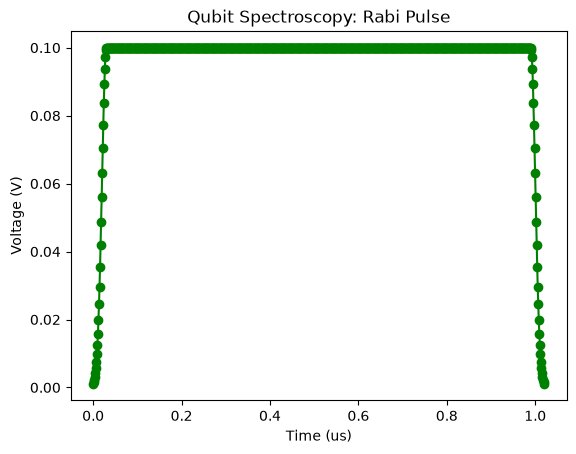

In [167]:
t = np.linspace(t_start, t_end, num_points) #will be used for generating the voltages
c_ops = collapse(a, T1, T2, wq, temperature) #initializing collapse operator
H_drive = (a + a.dag()) #Drive operator
omega_t = k_v * rabi_pulse(t, amplitude, flat_duration, sigma) # v_t = envelop(t,t_start,t_end,amplitude,sigma) #gaussian voltage envelop
# omega_t = k_v * omega_t
plt.plot(t, omega_t/k_v, marker='o', linestyle='-', color='g')
plt.title("Qubit Spectroscopy: Rabi Pulse")
plt.xlabel("Time (us)")
plt.ylabel("Voltage (V)")
plt.show()
# Arguments to pass arrays into drive coeff
args = {'omega_arr': omega_t, 't_arr': t}
rho_avg_t = avg_rho_trajectory(t,rho0,c_ops,num_trajectories,wq,alpha,w_drive,noise_std,H_drive,args)


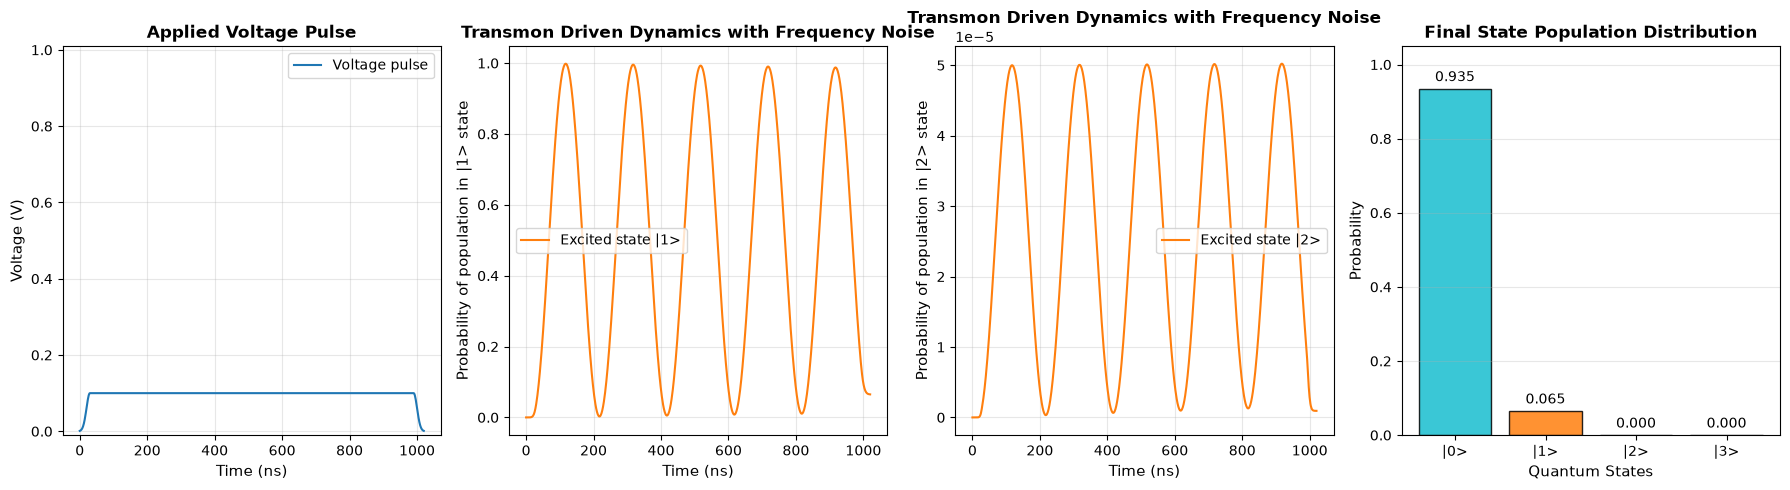

In [168]:
# Final state populations
P0_final = [expect(fock_dm(n, 0), rho) for rho in rho_avg_t]
P1_final = [expect(fock_dm(n, 1), rho) for rho in rho_avg_t]
P2_final = [expect(fock_dm(n, 2), rho) for rho in rho_avg_t]
P3_final = [expect(fock_dm(n, 3), rho) for rho in rho_avg_t]

#ploting
final_rho = rho_avg_t[-1]
probs = [expect(fock_dm(n, i), final_rho) for i in range(n)]
states = ["|0>", "|1>", "|2>", "|3>"]

fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(18, 5))

#subplot 1
ax1.plot(t*1e3,omega_t/k_v,label="Voltage pulse")
ax1.set_xlabel("Time (ns)", fontsize=11)
ax1.set_ylabel("Voltage (V)", fontsize=11)
ax1.set_title("Applied Voltage Pulse", fontsize=12, fontweight="bold")
ax1.set_ylim(-0.01, 1.01)
ax1.legend()
ax1.grid(True, alpha=0.3)

# subplot 2
ax2.plot(t * 1e3, P1_final, label="Excited state |1>", color="tab:orange")
ax2.set_xlabel("Time (ns)", fontsize=11)
ax2.set_ylabel("Probability of population in |1> state", fontsize=11)
ax2.set_title("Transmon Driven Dynamics with Frequency Noise", fontsize=12, fontweight="bold")
ax2.legend()
ax2.grid(True, alpha=0.3)

ax3.plot(t * 1e3, P2_final, label="Excited state |2>", color="tab:orange")
ax3.set_xlabel("Time (ns)", fontsize=11)
ax3.set_ylabel("Probability of population in |2> state", fontsize=11)
ax3.set_title("Transmon Driven Dynamics with Frequency Noise", fontsize=12, fontweight="bold")
ax3.legend()
ax3.grid(True, alpha=0.3)

# subplot 3
bars = ax4.bar(
    states,
    probs,
    color=["tab:cyan", "tab:orange", "tab:green", "tab:purple"],
    alpha=0.85,
    edgecolor="black",
    linewidth=1,
)
ax4.set_xlabel("Quantum States", fontsize=11)
ax4.set_ylabel("Probability", fontsize=11)
ax4.set_title("Final State Population Distribution", fontsize=12, fontweight="bold")
ax4.set_ylim(0, 1.05)
ax4.grid(True, axis="y", alpha=0.3)

for bar in bars:
  height = bar.get_height()
  ax4.annotate(
      f"{height:.3f}",
      xy=(bar.get_x() + bar.get_width() / 2, height),
      xytext=(0, 3),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=10,
  )

plt.tight_layout()
plt.show()

## Qubit spectroscopy

In [6]:
# Qubit parameters
n = 4 #no of states
a = destroy(n) #anhilation operator
rho0 = fock_dm(n, 0) #initial density matrix (This is where we can define our qubit state)
T1 = 40 #time in us
T2 = 35 #time in us
wq = 5011 #transmon freq in MHz
alpha = -500 #anharmonicity in MHz
temperature = 0.02 #Temperature at which processor is placed (in Kelvin) 
noise_std = 0.1 # W_q noise fluctuation in MHz
H_drive = (a + a.dag()) #Drive operator

c_ops = collapse(a, T1, T2, wq, temperature) #initializing collapse operator
k_v = 2 * np.pi * 25 #calibration factor, check below i have written the notes for it currenltly its 25Mhz 
num_trajectories = 50 #Add a loop for frequency noise (Quasi-static / 1/f style)


# Driving parameters
amplitude = 0.1 #max amplitude of the FPGA for ZCU111 currently our max voltage is 1V
w_drive = 5011  #frequency of the driving signal in MHz

sigma = 5e-3 #used in the gaussian envelop (in us)
t_start = 0 #start time of the pulse from the FPGA in us
resolution = 1.2e-3 #Resolution of our FPGA as of now taking it as 1.2ns 


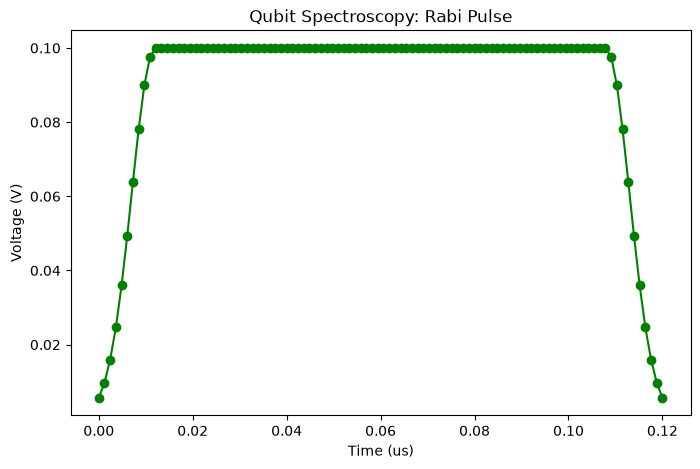

In [7]:
fitrange = list(range(4950, 5060, 10))#+ list(range(4900, 4990, 10))  + list(range(5010, 5100, 10))
fitrange.sort()
num_points = 100
t_end = num_points * resolution #end time of the pulse from the FPGA in us
flat_duration = (num_points - 20) * resolution  # Duration of the flat top in us
t = np.linspace(t_start, t_end, num_points) #will be used for generating the voltages

omega_t = k_v * rabi_pulse(t, amplitude, flat_duration, sigma) # v_t = envelop(t,t_start,t_end,amplitude,sigma) #gaussian voltage envelop

# plot the pulse and the probability of being in state |1> as a function of driving frequency
plt.figure(figsize=(8, 5))
plt.plot(t, omega_t/k_v, marker='o', linestyle='-', color='g')
plt.title("Qubit Spectroscopy: Rabi Pulse")
plt.xlabel("Time (us)")
plt.ylabel("Voltage (V)")
plt.show()

w_drive: 4950 MHz, P(|1>): 0.0013
w_drive: 4960 MHz, P(|1>): 0.0033
w_drive: 4970 MHz, P(|1>): 0.0075
w_drive: 4980 MHz, P(|1>): 0.0159
w_drive: 4990 MHz, P(|1>): 0.0346
w_drive: 5000 MHz, P(|1>): 0.1116
w_drive: 5010 MHz, P(|1>): 0.9315
w_drive: 5020 MHz, P(|1>): 0.0270
w_drive: 5030 MHz, P(|1>): 0.0086
w_drive: 5040 MHz, P(|1>): 0.0062
w_drive: 5050 MHz, P(|1>): 0.0045


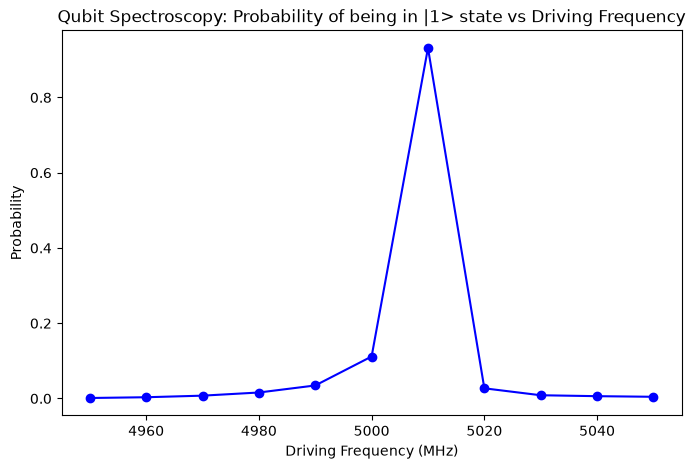

In [8]:
# Arguments to pass arrays into drive coeff
args = {'omega_arr': omega_t, 't_arr': t}
p1_values = []  # List to store the probabilities of being in state |1> for each w_drive
for w_drive in fitrange:  # Sweep w_drive from 4990 MHz to 5009 MHz
    rho_avg_t = avg_rho_trajectory(t,rho0,c_ops,num_trajectories,wq,alpha,w_drive,noise_std,H_drive,args)
    p1=expect(fock_dm(n, 1), rho_avg_t[-1])
    print(f"w_drive: {w_drive} MHz, P(|1>): {p1:.4f}")
    p1_values.append(p1)


plt.figure(figsize=(8, 5))
plt.plot(fitrange, p1_values, marker='o', linestyle='-', color='b')
plt.title("Qubit Spectroscopy: Probability of being in |1> state vs Driving Frequency")
plt.xlabel("Driving Frequency (MHz)")
plt.ylabel("Probability")
plt.show()

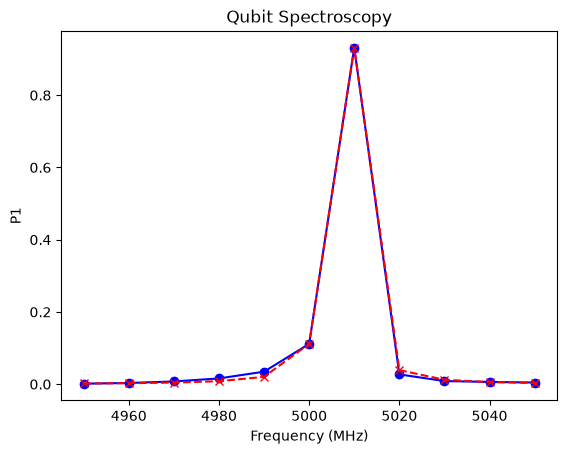

Fitted parameters: f0=5007.43 ± 0.39 MHz, gamma=0.03 ± 216.26 MHz, A=35211.91 ± 575625471.00, phi=0.00 ± 0.00


In [9]:
# fitting the data to a lorentzian function and showing the fitted curve with the original plot

popt, pcov = curve_fit(fit_lorentzian, fitrange, p1_values, p0=[5000, 16, 1, 0], method='trf', maxfev=10000)
plt.plot(fitrange, p1_values, marker='o', linestyle='-', color='b')
plt.plot(fitrange, fit_lorentzian(fitrange, *popt), marker='x', linestyle='--', color='r')
plt.xlabel('Frequency (MHz)')
plt.ylabel('P1')
plt.title('Qubit Spectroscopy')
plt.show()
# printing the fitted parameters and their uncertainties
perr = np.sqrt(np.diag(pcov))
fitted_f0, fitted_gamma, fitted_A, fitted_phi = popt
print(f"Fitted parameters: f0={fitted_f0:.2f} ± {perr[0]:.2f} MHz, gamma={fitted_gamma:.2f} ± {perr[1]:.2f} MHz, A={fitted_A:.2f} ± {perr[2]:.2f}, phi={fitted_phi:.2f} ± {perr[3]:.2f}")   

## Rabi Chevron experiment for qubit spectroscopy

In [10]:
# Qubit parameters
n = 4 #no of states
a = destroy(n) #anhilation operator
rho0 = fock_dm(n, 0) #initial density matrix (This is where we can define our qubit state)
T1 = 40 #time in us
T2 = 35 #time in us
wq = 5011 #transmon freq in MHz
alpha = -500 #anharmonicity in MHz
temperature = 0.02 #Temperature at which processor is placed (in Kelvin) 
noise_std = 0.1 # W_q noise fluctuation in MHz
H_drive = (a + a.dag()) #Drive operator

c_ops = collapse(a, T1, T2, wq, temperature) #initializing collapse operator
k_v = 2 * np.pi * 25 #calibration factor, check below i have written the notes for it currenltly its 25Mhz 
num_trajectories = 50 #Add a loop for frequency noise (Quasi-static / 1/f style)


# Driving parameters
amplitude = 0.1 #max amplitude of the FPGA for ZCU111 currently our max voltage is 1V
w_drive = 5011  #frequency of the driving signal in MHz

sigma = 5e-3 #used in the gaussian envelop (in us)
t_start = 0 #start time of the pulse from the FPGA in us
resolution = 1.2e-3 #Resolution of our FPGA as of now taking it as 1.2ns 
resolution

0.0012

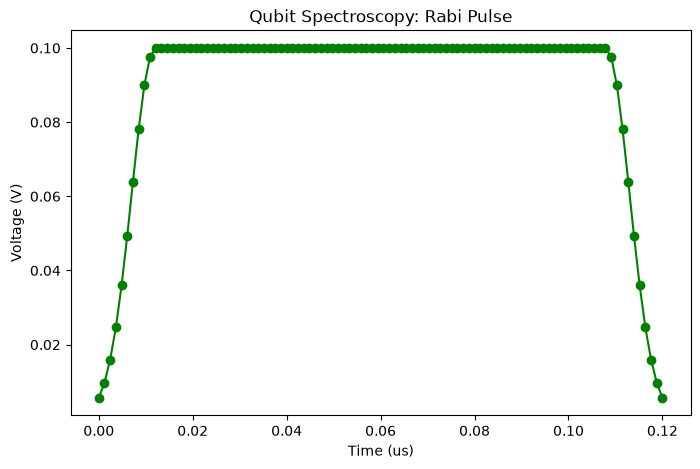

In [11]:

num_points = 100
t_end = num_points * resolution #end time of the pulse from the FPGA in us
flat_duration = (num_points - 20) * resolution  # Duration of the flat top in us
t = np.linspace(t_start, t_end, num_points) #will be used for generating the voltages

omega_t = k_v * rabi_pulse(t, amplitude, flat_duration, sigma) # v_t = envelop(t,t_start,t_end,amplitude,sigma) #gaussian voltage envelop

# plot the pulse and the probability of being in state |1> as a function of driving frequency
plt.figure(figsize=(8, 5))
plt.plot(t, omega_t/k_v, marker='o', linestyle='-', color='g')
plt.title("Qubit Spectroscopy: Rabi Pulse")
plt.xlabel("Time (us)")
plt.ylabel("Voltage (V)")
plt.show()

In [12]:
times_end = []
p1_times = []
fitrange = list(range(5000, 5020, 1))#+ list(range(4900, 4990, 10))  + list(range(5010, 5100, 10))
fitrange.sort()
for num_points in [100, 150, 200, 250, 300, 350, 400, 450, 500]:#[500, 750, 1000, 1250, 1500]:
    t_end = num_points * resolution #end time of the pulse from the FPGA in us
    flat_duration = (num_points - 20) * resolution  # Duration of the flat top in us
    t = np.linspace(t_start, t_end, num_points)
    omega_t = k_v * rabi_pulse(t, amplitude, flat_duration, sigma)
    times_end.append(t_end)

    # Arguments to pass arrays into drive coeff
    args = {'omega_arr': omega_t, 't_arr': t}
    p1_values = []  # List to store the probabilities of being in state |1> for each w_drive
    for w_drive in fitrange:  # Sweep w_drive from 4990 MHz to 5009 MHz
        rho_avg_t = avg_rho_trajectory(t,rho0,c_ops,num_trajectories,wq,alpha,w_drive,noise_std,H_drive,args)
        p1=expect(fock_dm(n, 1), rho_avg_t[-1])
        print(f"w_drive: {w_drive} MHz, P(|1>): {p1:.4f}")
        p1_values.append(p1)
        
    # plt.figure(figsize=(8, 5))
    # plt.plot(fitrange, p1_values, marker='o', linestyle='-', color='b')
    # plt.title("Qubit Spectroscopy: Probability of being in |1> state vs Driving Frequency")
    # plt.xlabel("Driving Frequency (MHz)")
    # plt.ylabel("Probability")
    # plt.show()  
    print(f"Completed for num_points={num_points}, t_end={t_end:.3f} us")
    print(f"p1_values: {p1_values}")
    p1_times.append(p1_values)



w_drive: 5000 MHz, P(|1>): 0.1117
w_drive: 5001 MHz, P(|1>): 0.0747
w_drive: 5002 MHz, P(|1>): 0.0298
w_drive: 5003 MHz, P(|1>): 0.0021
w_drive: 5004 MHz, P(|1>): 0.0152
w_drive: 5005 MHz, P(|1>): 0.0810
w_drive: 5006 MHz, P(|1>): 0.2201
w_drive: 5007 MHz, P(|1>): 0.4035
w_drive: 5008 MHz, P(|1>): 0.6094
w_drive: 5009 MHz, P(|1>): 0.7964
w_drive: 5010 MHz, P(|1>): 0.9345
w_drive: 5011 MHz, P(|1>): 0.9810
w_drive: 5012 MHz, P(|1>): 0.9342
w_drive: 5013 MHz, P(|1>): 0.8064
w_drive: 5014 MHz, P(|1>): 0.6213
w_drive: 5015 MHz, P(|1>): 0.4125
w_drive: 5016 MHz, P(|1>): 0.2288
w_drive: 5017 MHz, P(|1>): 0.0926
w_drive: 5018 MHz, P(|1>): 0.0184
w_drive: 5019 MHz, P(|1>): 0.0017
Completed for num_points=100, t_end=0.120 us
p1_values: [0.11170625917097715, 0.07473423082799559, 0.029836797585214618, 0.002137368949680869, 0.015204124940847006, 0.08101812898626794, 0.22008620127062029, 0.4035368537699712, 0.6093549559107765, 0.7964252648267354, 0.9344669472057907, 0.9810199262994114, 0.93422091697

{'f01_MHz': np.float64(5011.026469808752), 'fRabi_MHz': np.float64(5.000324720111527), 'baseline': np.float64(0.0016182311873044323), 'contrast': np.float64(0.987530266521295), 'phase_t': np.float64(0.011675066078654981)}


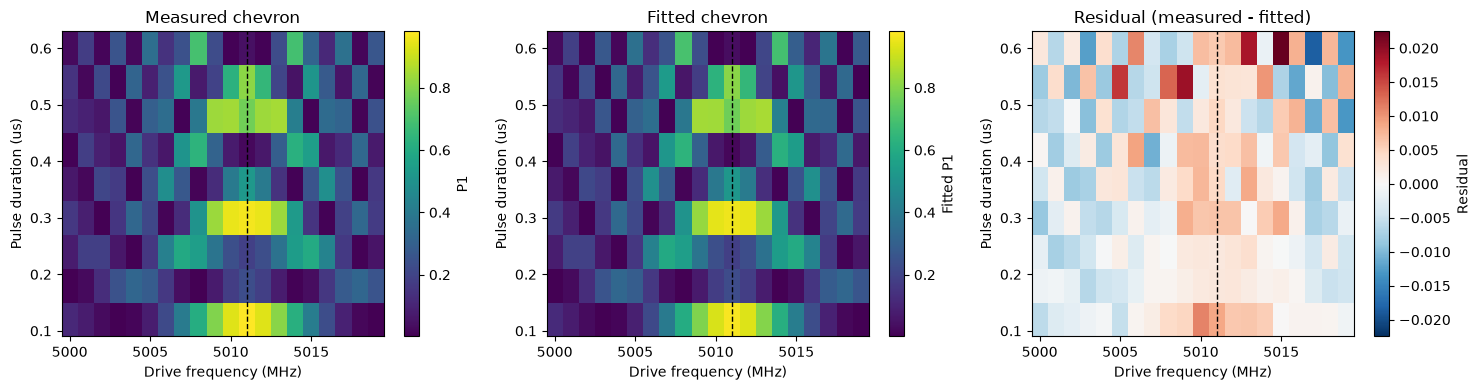

In [13]:
p1_times = np.array(p1_times)
result = fit_chevron(np.array(fitrange),times_end, p1_times,p_guess=[5007, 6, 0, 1, 0])
print(result)
plot_chevron_fit(np.array(fitrange), times_end, p1_times, result)

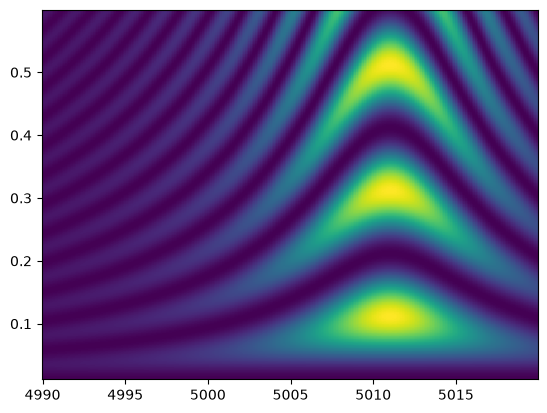

In [15]:
# plot 2d graph of the cheveron model with frequency range 4500 to 5500 and time range from 100 to 500 with step size of 50
F, T = np.meshgrid(np.arange(4990, 5020, 0.1), resolution*np.arange(10, 500, 1))
plt.pcolormesh(F, T, chevron_model((F, T), result["f01_MHz"], result["fRabi_MHz"], result["baseline"], result["contrast"], result["phase_t"]), shading="auto")


## Rabi Oscillation

In [65]:
# Qubit parameters
n = 4 #no of states
a = destroy(n) #anhilation operator
rho0 = fock_dm(n, 0) #initial density matrix (This is where we can define our qubit state)
T1 = 40 #time in us
T2 = 35 #time in us
wq = 5000 #transmon freq in MHz
alpha = -500 #anharmonicity in MHz
temperature = 0.02 #Temperature at which processor is placed (in Kelvin) 
noise_std = 0.1 # W_q noise fluctuation in MHz
H_drive = (a + a.dag()) #Drive operator

c_ops = collapse(a, T1, T2, wq, temperature) #initializing collapse operator
k_v = 2 * np.pi * 25 #calibration factor, check below i have written the notes for it currenltly its 25Mhz 
num_trajectories = 50 #Add a loop for frequency noise (Quasi-static / 1/f style)


# Driving parameters
amplitude = 0.1 #max amplitude of the FPGA for ZCU111 currently our max voltage is 1V
w_drive = 5000  #frequency of the driving signal in MHz

sigma = 5e-3 #used in the gaussian envelop (in us)
t_start = 0 #start time of the pulse from the FPGA in us
resolution = 1.2e-3 #Resolution of our FPGA as of now taking it as 1.2ns 


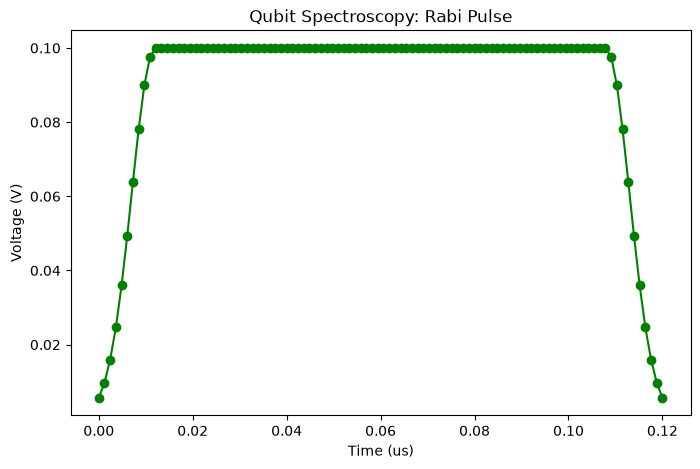

In [66]:

num_points = 100
t_end = num_points * resolution #end time of the pulse from the FPGA in us
flat_duration = (num_points - 20) * resolution  # Duration of the flat top in us
t = np.linspace(t_start, t_end, num_points) #will be used for generating the voltages

omega_t = k_v * rabi_pulse(t, amplitude, flat_duration, sigma) # v_t = envelop(t,t_start,t_end,amplitude,sigma) #gaussian voltage envelop

# plot the pulse and the probability of being in state |1> as a function of driving frequency
plt.figure(figsize=(8, 5))
plt.plot(t, omega_t/k_v, marker='o', linestyle='-', color='g')
plt.title("Qubit Spectroscopy: Rabi Pulse")
plt.xlabel("Time (us)")
plt.ylabel("Voltage (V)")
plt.show()

In [72]:
p1_values = []  # List to store the probabilities of being in state |1> for each w_drive
w_drive = 5000  #frequency of the driving signal in MHz
t_end_list = []
flat_duration_list = []
for num_points in range(20, 350, 10):  
    t_end = num_points * resolution #end time of the pulse from the FPGA in us
    flat_duration = (num_points - 20) * resolution  # Duration of the flat top in us
    t = np.linspace(t_start, t_end, num_points) #will be used for generating the voltages
    omega_t = k_v * rabi_pulse(t, amplitude, flat_duration, sigma) # v_t = envelop(t,t_start,t_end,amplitude,sigma) #gaussian voltage envelop
    args = {'omega_arr': omega_t, 't_arr': t}
    rho_avg_t = avg_rho_trajectory(t,rho0,c_ops,num_trajectories,wq,alpha,w_drive,noise_std,H_drive,args)
    p1=expect(fock_dm(n, 1), rho_avg_t[-1])
    print(f"t_end: {t_end} us, flat_duration: {flat_duration} us, P(|1>): {p1:.4f}")
    p1_values.append(p1)
    t_end_list.append(t_end)
    flat_duration_list.append(flat_duration)


t_end: 0.023999999999999997 us, flat_duration: 0.0 us, P(|1>): 0.0370
t_end: 0.036 us, flat_duration: 0.011999999999999999 us, P(|1>): 0.1389
t_end: 0.047999999999999994 us, flat_duration: 0.023999999999999997 us, P(|1>): 0.2914
t_end: 0.06 us, flat_duration: 0.036 us, P(|1>): 0.4731
t_end: 0.072 us, flat_duration: 0.047999999999999994 us, P(|1>): 0.6584
t_end: 0.08399999999999999 us, flat_duration: 0.06 us, P(|1>): 0.8213
t_end: 0.09599999999999999 us, flat_duration: 0.072 us, P(|1>): 0.9390
t_end: 0.10799999999999998 us, flat_duration: 0.08399999999999999 us, P(|1>): 0.9948
t_end: 0.12 us, flat_duration: 0.09599999999999999 us, P(|1>): 0.9813
t_end: 0.13199999999999998 us, flat_duration: 0.10799999999999998 us, P(|1>): 0.8997
t_end: 0.144 us, flat_duration: 0.12 us, P(|1>): 0.7622
t_end: 0.156 us, flat_duration: 0.13199999999999998 us, P(|1>): 0.5879
t_end: 0.16799999999999998 us, flat_duration: 0.144 us, P(|1>): 0.4015
t_end: 0.18 us, flat_duration: 0.156 us, P(|1>): 0.2290
t_end: 0

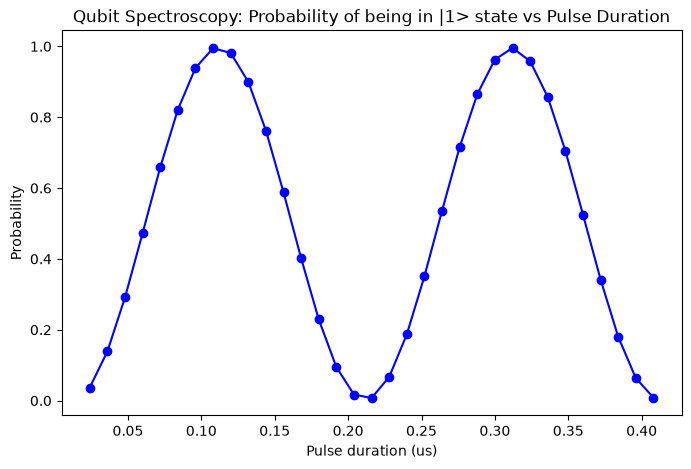

In [73]:

plt.figure(figsize=(8, 5))
plt.plot(t_end_list, p1_values, marker='o', linestyle='-', color='b')
plt.title("Qubit Spectroscopy: Probability of being in |1> state vs Pulse Duration")
plt.xlabel("Pulse duration (us)")
plt.ylabel("Probability")
plt.show()

0.997385816799842 2.4992955169231177 -0.18260576592948463


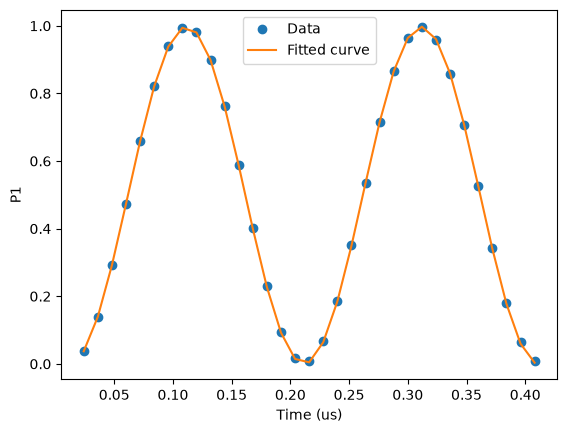

In [ ]:
# fit p1_values vs t_end_list to a sin^2 function and show the fitted curve with the original plot


p1_values = np.array(p1_values)
t_end_list = np.array(t_end_list)

popt, pcov = curve_fit(sin_squared, t_end_list, p1_values, p0=[1, 5, 0])
# also print the fitted values
print(popt[0], popt[1], popt[2])

plt.plot(t_end_list, p1_values, 'o', label='Data')
plt.plot(t_end_list, sin_squared(t_end_list, *popt), '-', label='Fitted curve')
plt.xlabel('Time (us)')
plt.ylabel('P1')
plt.legend()
plt.show()